Problem Statement

The rapid growth of digital financial transactions has increased the risk of money laundering and fraudulent activities. Traditional rule-based monitoring systems are often unable to detect complex and evolving suspicious patterns, leading to delayed identification of illegal activities, increased financial losses, and compliance challenges for banks and financial institutions. This project aims to build an intelligent Anti-Money Laundering (AML) detection system that can analyze transaction data, identify suspicious behavior, and assist in early risk detection with higher accuracy and efficiency.

BUSINESS PROBLEM 

Financial organizations face a major challenge in monitoring large volumes of transactions while minimizing false positives and missing genuine suspicious cases. Manual investigation is time-consuming, expensive, and often ineffective against sophisticated laundering methods. Therefore, there is a strong need for an automated, data-driven solution that can flag high-risk transactions in real time and support compliance officers in making informed decisions.


In [2]:
import numpy as np 
import pandas as pd

In [2]:
import pandas as pd
import numpy as np

# Load dataset
print("Loading dataset...")
df = pd.read_csv("Medium_Trans.csv")
print("Original shape:", df.shape)

# ==========================================
# NEW STEP: Create exactly 1.5 Lakh rows with 70/30 split
# ==========================================
target_total = 150000
target_minority = int(target_total * 0.30)  # 45,000 (Class 1)
target_majority = target_total - target_minority  # 105,000 (Class 0)

# Separate the two classes
df_majority = df[df['Is Laundering'] == 0]
df_minority = df[df['Is Laundering'] == 1]

# Undersample the majority class (without replacement)
df_majority_sampled = df_majority.sample(n=target_majority, random_state=42)

# Oversample the minority class (WITH replacement because we need 45k but only have ~16k)
df_minority_sampled = df_minority.sample(n=target_minority, replace=True, random_state=42)

# Combine, shuffle so they aren't grouped together, and reset index
df = pd.concat([df_majority_sampled, df_minority_sampled])
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("\nShape after 70/30 sampling:", df.shape)
print("\nNew 'Is Laundering' Balance:")
print(df['Is Laundering'].value_counts(normalize=True) * 100)


# ==========================================
# PREVIOUS STEP: Missing Value Injection
# ==========================================
rng = np.random.default_rng(42)

# Track how many missing values each row has to ensure we don't delete too much
nan_counts = np.zeros(len(df), dtype=int)
MAX_NANS_PER_ROW = 3

print("\nInjecting missing values...")
for col in df.columns:
    # Generate a random percentage between 0.5% and 2.5% for this specific column
    col_fraction = rng.uniform(0.005, 0.025) 
    n = int(len(df) * col_fraction)

    # Find rows that currently have fewer than the maximum allowed missing values
    eligible_rows = np.where(nan_counts < MAX_NANS_PER_ROW)[0]

    # Ensure we don't try to select more rows than are eligible
    n = min(n, len(eligible_rows))

    # Pick random rows strictly from the eligible pool
    random_rows = rng.choice(eligible_rows, size=n, replace=False)

    # Increment the NaN counter for the selected rows
    nan_counts[random_rows] += 1

    # Inject the NaNs
    df.iloc[random_rows, df.columns.get_loc(col)] = np.nan

print("\nMissing values after random removal (varying per column):")
print(df.isna().sum())
print(f"Maximum missing values in any single row: {nan_counts.max()}")


# ==========================================
# PREVIOUS STEP: Fill Missing Values
# ==========================================
print("\nFilling missing values...")
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            # Fill numeric columns with median
            df[col] = df[col].fillna(df[col].median())
        else:
            # Fill categorical columns with mode
            mode_values = df[col].mode(dropna=True)
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

print("\nMissing values after filling:")
print(df.isna().sum())

print("\nFinal shape:", df.shape)

# Save cleaned and downsampled dataset
df.to_csv("LI-Medium_Trans_150k_70-30_cleaned.csv", index=False)
print("\nDataset sampled, cleaned, and saved successfully!")

Loading dataset...
Original shape: (31251483, 11)

Shape after 70/30 sampling: (150000, 11)

New 'Is Laundering' Balance:
Is Laundering
0    70.0
1    30.0
Name: proportion, dtype: float64

Injecting missing values...

Missing values after random removal (varying per column):
Timestamp             3071
From Bank             2993
Account               3061
To Bank               1213
Account.1             3020
Amount Received       2598
Receiving Currency    1505
Amount Paid           2873
Payment Currency      1909
Payment Format        2879
Is Laundering         2437
dtype: int64
Maximum missing values in any single row: 3

Filling missing values...

Missing values after filling:
Timestamp             0
From Bank             0
Account               0
To Bank               0
Account.1             0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64

Final shape: (150000, 11)

Datase

Q1. Transaction amount and laundering status

Question: Is the mean transaction amount received by laundering-labelled transactions different from that of legitimate transactions?

In [3]:
df1=pd.read_csv("LI-Medium_Trans_150k_70-30_cleaned.csv")

In [4]:
df1.head()

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 13:45,34519.0,800F0B450,38244.0,820752210,265068.02,US Dollar,265068.02,US Dollar,Cheque,0.0
1,2022/09/08 20:25,7565.0,807304A80,227789.0,81A721F40,33.18,Euro,33.18,Euro,Credit Card,0.0
2,2022/09/19 16:07,41590.0,8110473F0,137920.0,80E6913F0,1293.46,US Dollar,1293.46,US Dollar,Cheque,1.0
3,2022/09/10 11:41,1315.0,8031445E0,4547.0,803854260,533.02,Euro,533.02,Euro,ACH,1.0
4,2022/09/12 10:20,2140157.0,833D48180,2141260.0,833D487C0,4546.59,Australian Dollar,4546.59,Australian Dollar,ACH,1.0


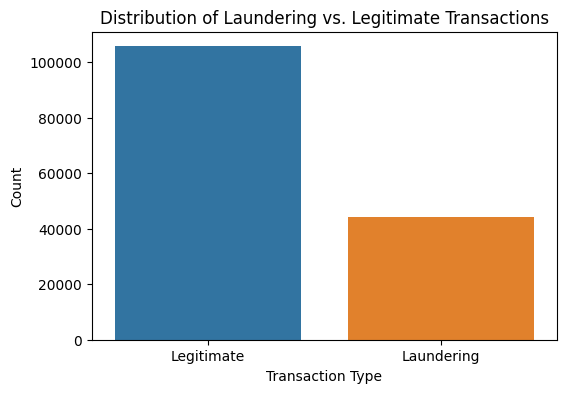

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Count the frequencies of each class directly from the column
counts = df1["Is Laundering"].value_counts()

# 2. Map the indices to readable labels for the plot
counts.index = counts.index.map({0: "Legitimate", 1: "Laundering"})

# 3. Plot using Seaborn
plt.figure(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False)

# 4. Add labels and title
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.title("Distribution of Laundering vs. Legitimate Transactions")

plt.show()


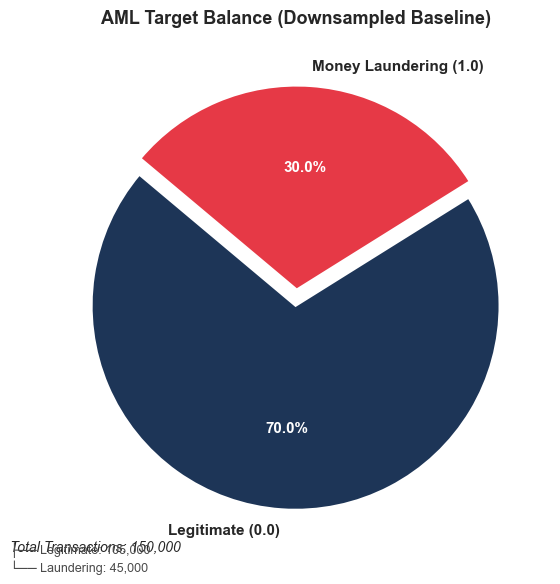

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the class labels and precise counts from your dataset
labels = ['Legitimate (0.0)', 'Money Laundering (1.0)']
counts = [105000, 45000]

# 2. Set the professional corporate palette
# Deep Navy for Legitimate volume, soft Crimson/Coral for Fraud alerts
colors = ['#1d3557', '#e63946']

# 3. Configure the layout structure
plt.figure(figsize=(6, 6), dpi=100)
sns.set_theme(style="white")

# 4. Generate the pie chart
wedges, texts, autotexts = plt.pie(
    counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=(0, 0.08),  # Suspend/Explode the fraud wedge for visual emphasis
    shadow=False,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5, 'antialiased': True},
    textprops={'fontsize': 11, 'weight': 'bold'}
)

# 5. Format internal slice typography for readability
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(11)

# 6. Add precision counts directly onto the plot layout
plt.text(-1.4, -1.2, f"Total Transactions: {sum(counts):,}", fontsize=10, style='italic')
plt.text(-1.4, -1.3, f"├── Legitimate: {counts[0]:,}\n└── Laundering: {counts[1]:,}", fontsize=9, color='#4a4a4a')

# 7. Finalize presentation configurations
plt.title("AML Target Balance (Downsampled Baseline)", fontsize=13, weight='bold', pad=20)
plt.tight_layout()

# Save the visualization to your project directory
plt.savefig('aml_target_composition.png', bbox_inches='tight', dpi=300)
plt.show()


In [6]:
df1['Payment Format'].unique()

array(['Cheque', 'Credit Card', 'ACH', 'Reinvestment', 'Wire', 'Bitcoin',
       'Cash'], dtype=object)

1)Do suspicious transactions involve different amounts?

Business question: Is the average amount received significantly different between laundering transactions and legitimate transactions?


H_0: The mean transaction amounts are equal.
    
    mu_L= mu_N 



H_1:  The mean transaction amounts are not equal. 
    
    mu_L != mu_N 


TEST : WLECH T TEST 

--- LAUNDERING TRANSACTIONS ---
Mean  : $5,461,686.87
Median: $3,286.21

--- LEGITIMATE TRANSACTIONS ---
Mean  : $526,315.39
Median: $937.64


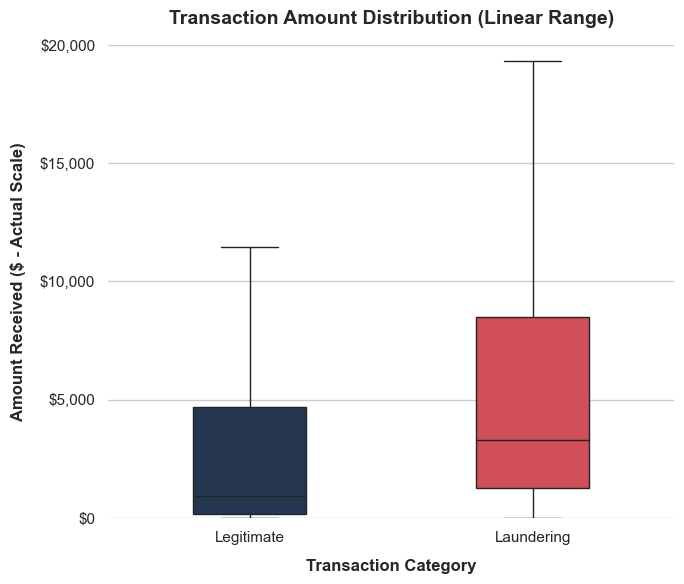

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Filter for US Dollar transactions safely
df1 = df1[df1["Receiving Currency"] == "US Dollar"].copy()

# 2. Extract transaction amounts
laundering = df1.loc[df1["Is Laundering"] == 1, "Amount Received"].dropna()
legitimate = df1.loc[df1["Is Laundering"] == 0, "Amount Received"].dropna()

# Print central tendencies
print("--- LAUNDERING TRANSACTIONS ---")
print(f"Mean  : ${np.mean(laundering):,.2f}")
print(f"Median: ${np.median(laundering):,.2f}")

print("\n--- LEGITIMATE TRANSACTIONS ---")
print(f"Mean  : ${np.mean(legitimate):,.2f}")
print(f"Median: ${np.median(legitimate):,.2f}")

# 3. Box plot configuration
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 6))

ax = sns.boxplot(
    data=df1,
    x="Is Laundering",
    y="Amount Received",
    hue="Is Laundering",  # Maps categories to colors properly
    palette=["#1d3557", "#e63946"],  # Dark Blue for Legit, Red for Laundering
    width=0.4,
    showfliers=False,  # Hides outliers beyond the whiskers to keep the boxes readable
    legend=False,
)

# 4. Format X-axis
plt.xticks(ticks=[0, 1], labels=["Legitimate", "Laundering"], fontsize=11)

# 5. Apply the requested custom Y-axis scale and tick marks
plt.ylim(0, 20000)  # Caps the view at your highest requested value
plt.yticks([0, 5000, 10000,15000, 20000])  # Explicitly forces markers at your targets

# Format the Y-axis labels with clean dollar signs and commas
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, loc: f"${y:,.0f}"))

plt.xlabel("Transaction Category", fontsize=12, fontweight="bold", labelpad=10)
plt.ylabel(
    "Amount Received ($ - Actual Scale)", fontsize=12, fontweight="bold", labelpad=10
)
plt.title(
    "Transaction Amount Distribution (Linear Range)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Clean up chart borders
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()


In [6]:
from statsmodels.stats.api import ttest_ind

T_stats,p_value,ddof=ttest_ind(laundering,legitimate,alternative='two-sided')

In [7]:
if(p_value<0.05):
    print("Reject the Null Hypothesis")
else:
    print('We Fail to Reject The Null Hypothesis')

Reject the Null Hypothesis


Conclusion : We Have statistically Significant and Enough Evidence to conclude that the Average of Legitmate Transaction and Average of Laudering Transactions are Not Equal 

Q2. Payment format and laundering status

Question: Is payment format independent of laundering status


H0 : Payement Format is Independent  of Laundering Status

H1 : Payment Format is Dependent on Laundering Status


TEST : Chi Square Degree of Association


is a Transaction made through a payment method A is more likely to be flagged as compared to Method B

Checking which payment method is more likelly to be flaggedd 


In [8]:
df1.head()

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 13:45,34519.0,800F0B450,38244.0,820752210,265068.02,US Dollar,265068.02,US Dollar,Cheque,0.0
2,2022/09/19 16:07,41590.0,8110473F0,137920.0,80E6913F0,1293.46,US Dollar,1293.46,US Dollar,Cheque,1.0
7,2022/09/06 02:28,24531.0,8193E9E00,151399.0,822F37A70,75561.52,US Dollar,75561.52,US Dollar,Cheque,0.0
17,2022/09/06 02:27,70.0,10042B660,21418.0,8052E36B0,39.30,US Dollar,39.30,US Dollar,Credit Card,1.0
18,2022/09/01 15:05,1488.0,803139A40,119334.0,809368890,320.30,US Dollar,320.30,US Dollar,ACH,0.0


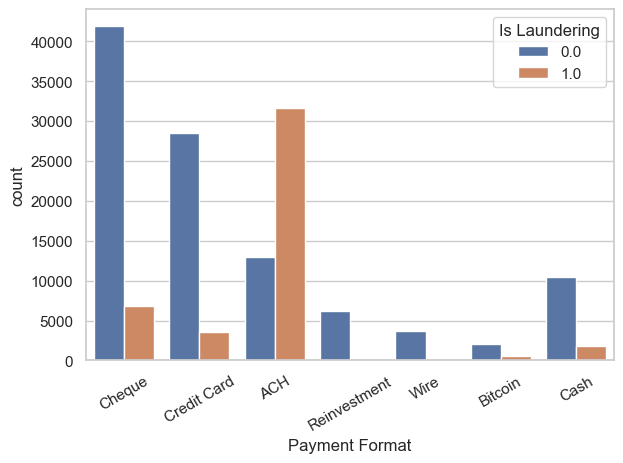

In [14]:
# Plot using the original, unfiltered dataframe (df) to see all formats
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=df1, x='Payment Format', hue='Is Laundering')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [10]:
from statsmodels.stats.contingency_tables import Table
import statsmodels.stats as sm 
Data=pd.crosstab(df1['Is Laundering'],df1['Payment Format'])

test=Table(Data)
result=test.test_nominal_association()

p_value=result.pvalue
print("Statistics :",result.statistic)
print("P_value :",p_value)


Statistics : 21130.71008584303
P_value : 0.0


In [11]:
if(p_value<0.05):
    print("Reject the Null Hypothesis")
else:
    print("We fail to Reject the Null Hypothesis")

Reject the Null Hypothesis


Conclusion : There is sufficient statistical evidence to conclude that payment format and laundering status are significantly associated in the dataset.

3) Do transaction amounts differ across payment formats?

Business question: Is the mean amount received significantly different across the payment formats used in the transaction dataset?

H0:Average Amount Received is same Across all Payment format 


H1 :Average Amount Received is different across all Payment format 


Test : ONE-WAY-ANOVA


In [12]:
df1.head()

,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 13:45,34519.0,800F0B450,38244.0,820752210,265068.02,US Dollar,265068.02,US Dollar,Cheque,0.0
2,2022/09/19 16:07,41590.0,8110473F0,137920.0,80E6913F0,1293.46,US Dollar,1293.46,US Dollar,Cheque,1.0
7,2022/09/06 02:28,24531.0,8193E9E00,151399.0,822F37A70,75561.52,US Dollar,75561.52,US Dollar,Cheque,0.0
17,2022/09/06 02:27,70.0,10042B660,21418.0,8052E36B0,39.30,US Dollar,39.30,US Dollar,Credit Card,1.0
18,2022/09/01 15:05,1488.0,803139A40,119334.0,809368890,320.30,US Dollar,320.30,US Dollar,ACH,0.0


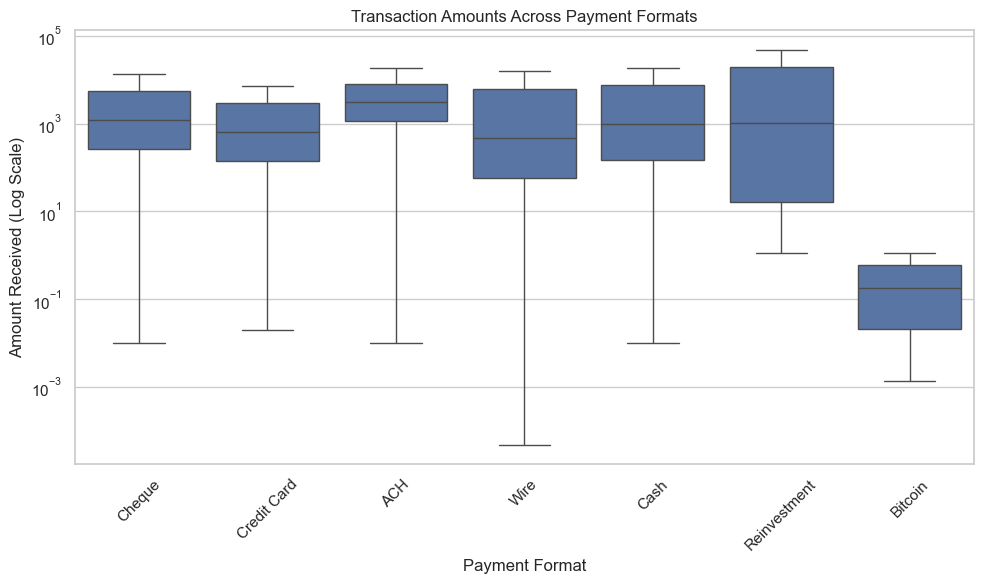

In [13]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df1,
    x="Payment Format",
    y="Amount Received",
    showfliers=False
)

plt.yscale("log")
plt.title("Transaction Amounts Across Payment Formats")
plt.xlabel("Payment Format")
plt.ylabel("Amount Received (Log Scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [14]:
from statsmodels.formula.api import ols

mod= ols('Q("Amount Received") ~ Q("Payment Format")', data=df1).fit()

anova=sm.api.anova_lm(mod,typ=2)

In [15]:
anova

,sum_sq,df,F,PR(>F)
"Q(""Payment Format"")",3.102858e+17,6.0,5.820004,0.000004
Residual,5.111893e+20,57530.0,NaN,NaN


In [16]:
#DONE BY WLECH _ ANNOVA :- USED Becuase the ols model was giving extreme rightly skewed values and wlech do no assume equal variance
import statsmodels.stats.oneway as oneway

groups = [
    group["Amount Received"].dropna().to_numpy()
    for _, group in df1.groupby("Payment Format")
]

result = oneway.anova_oneway(groups, use_var="unequal")
p_value=result.pvalue

print("Test_Statistics :",result.statistic)
print("P_Value :",p_value)

Test_Statistics : 11.44336299491311
P_Value : 8.895800328914013e-12


In [17]:
if(p_value<0.05):
    print("Reject The Null Hypothesis")
else:
    print("We Fail To Reject the Null Hypothesis")

Reject The Null Hypothesis


Conclusion : There is statistically significant evidence that the mean amount received differs across payment formats.


4 )To Prove a Significant Drop (Pre vs. Post Event)

Determine dramatic drop observed around September 16, 2022 represents a significant departure from normal activity


Hypothesis:

H0: The mean daily transaction volume is the same before and after September 16.

H1: The mean daily transaction volume is significantly lower after September 16.


TEST:Two-Sample t-Test.

Daily counts derived from the ORIGINAL dataset
Pre-event dates: 2022-09-01 to 2022-09-15
Post-event dates: 2022-09-16 to 2022-09-26
Number of pre-event days: 15
Number of post-event days: 11
Pre-event mean daily volume: 1886267.4
Post-event mean daily volume: 268860.7272727273

--- Welch Two-Sample t-Test Results ---
T-statistic: 4.4625
Degrees of freedom: 22.37
P-value: 9.41255e-05
Significance level: 0.05

Decision: Reject H0.
Conclusion: There is statistically significant evidence that mean daily transaction volume was higher before September 16 than during September 16–26.


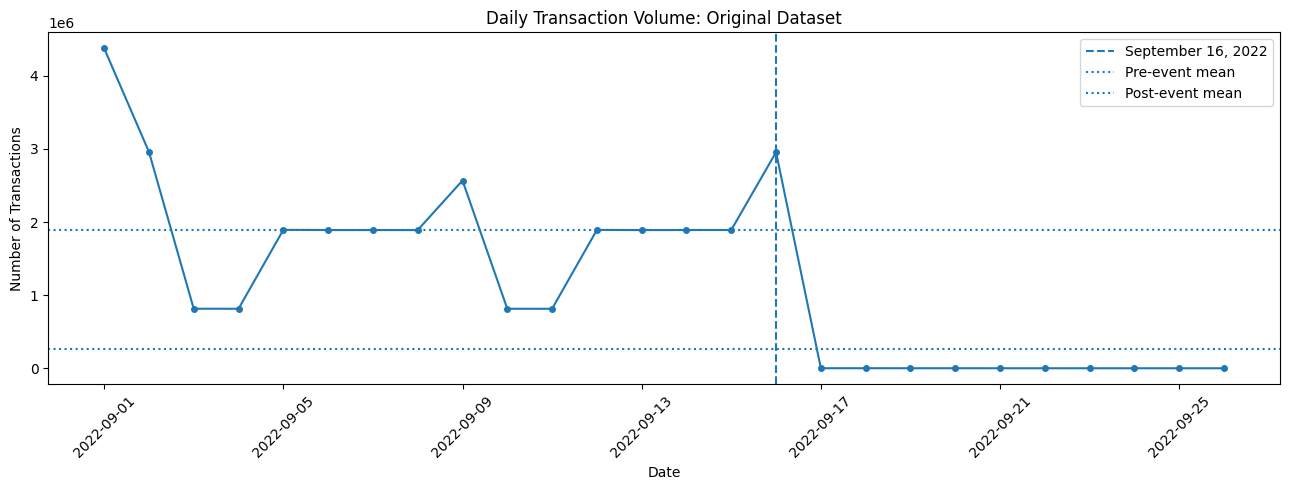

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.stats.weightstats as ws

# Read ONLY the timestamp column from the original dataset.
# This avoids using the sampled/oversampled 150,000-row dataset.
timestamp_df = pd.read_csv(
    "Medium_Trans.csv",
    usecols=["Timestamp"]
)

timestamp_df["Timestamp"] = pd.to_datetime(
    timestamp_df["Timestamp"],
    errors="coerce"
)
timestamp_df = timestamp_df.dropna(subset=["Timestamp"])

# Count the actual transactions recorded on each day in the ORIGINAL dataset.
daily_volume = (
    timestamp_df
    .set_index("Timestamp")
    .resample("D")
    .size()
    .rename("Transaction_Count")
)

# Compare September 1–15 with September 16–26, 2022.
pre_start = pd.Timestamp("2022-09-01")
event_date = pd.Timestamp("2022-09-16")
post_end_exclusive = pd.Timestamp("2022-09-27")  # includes Sept 26

# Create complete date ranges so every calendar day is represented.
pre_dates = pd.date_range(pre_start, event_date - pd.Timedelta(days=1), freq="D")
post_dates = pd.date_range(event_date, post_end_exclusive - pd.Timedelta(days=1), freq="D")

# Reindex to the intended windows. Missing calendar dates are treated as zero
# only if the source dataset is known to cover these dates completely.
pre_event_volume = daily_volume.reindex(pre_dates, fill_value=0).to_numpy()
post_event_volume = daily_volume.reindex(post_dates, fill_value=0).to_numpy()

print("Daily counts derived from the ORIGINAL dataset")
print("Pre-event dates:", pre_dates.min().date(), "to", pre_dates.max().date())
print("Post-event dates:", post_dates.min().date(), "to", post_dates.max().date())
print("Number of pre-event days:", len(pre_event_volume))
print("Number of post-event days:", len(post_event_volume))
print("Pre-event mean daily volume:", pre_event_volume.mean())
print("Post-event mean daily volume:", post_event_volume.mean())

# Confirm the source data contains records in both selected windows.
if pre_event_volume.sum() == 0 or post_event_volume.sum() == 0:
    raise ValueError(
        "One of the selected date windows has no transactions. "
        "Check the actual date range in Medium_Trans.csv before testing."
    )

# H0: mean(pre) <= mean(post)
# H1: mean(pre) > mean(post)
# 'larger' tests whether the first sample mean is greater than the second.
# Welch's test is used because equal variances have not been established.
t_stat, p_value, df = ws.ttest_ind(
    x1=pre_event_volume,
    x2=post_event_volume,
    alternative="larger",
    usevar="unequal"
)

alpha = 0.05

print("\n--- Welch Two-Sample t-Test Results ---")
print(f"T-statistic: {t_stat:.4f}")
print(f"Degrees of freedom: {df:.2f}")
print(f"P-value: {p_value:.6g}")
print(f"Significance level: {alpha}")

if p_value < alpha:
    print("\nDecision: Reject H0.")
    print(
        "Conclusion: There is statistically significant evidence that "
        "mean daily transaction volume was higher before September 16 "
        "than during September 16–26."
    )
else:
    print("\nDecision: Fail to reject H0.")
    print(
        "Conclusion: There is insufficient statistical evidence that "
        "mean daily transaction volume was higher before September 16."
    )

# Plot the actual daily transaction counts used in the analysis.
plot_dates = pre_dates.append(post_dates)
plot_counts = np.concatenate([pre_event_volume, post_event_volume])

plt.figure(figsize=(13, 5))
plt.plot(plot_dates, plot_counts, marker="o", markersize=4)
plt.axvline(event_date, linestyle="--", label="September 16, 2022")
plt.axhline(pre_event_volume.mean(), linestyle=":", label="Pre-event mean")
plt.axhline(post_event_volume.mean(), linestyle=":", label="Post-event mean")
plt.title("Daily Transaction Volume: Original Dataset")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


<Axes: >

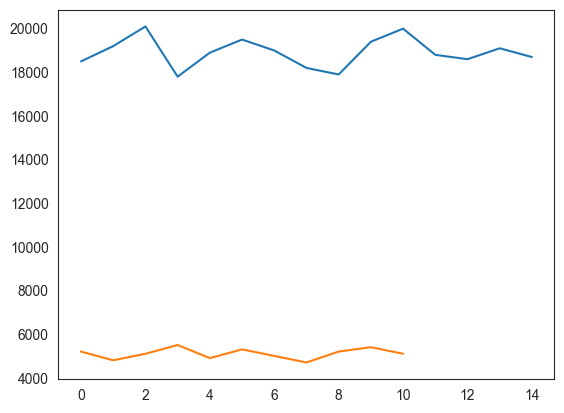

In [6]:
sns.lineplot(pre_event_volume)
sns.lineplot(post_event_volume)

 It maps daily transaction volumes over time, splitting the dataset into two distinct periods Pre(Pre) and Post(orange) 

Future Scope

This project can be extended in several ways in the future. Real-time fraud monitoring can be implemented using streaming data and APIs for instant detection. Advanced machine learning models and explainable AI techniques can be incorporated to improve prediction accuracy and provide clear reasons for flagged transactions. The system can also be expanded to include network analysis, customer behavior profiling, and integration with banking compliance dashboards. In the long term, this solution can evolve into a robust financial crime detection platform that supports not only AML but also related areas such as fraud detection and risk analysis.

Conclusion

In conclusion, this project demonstrates the importance of using machine learning to strengthen financial security and improve anti-money laundering efforts. By automating the detection of suspicious transactions, the system reduces human effort, improves decision-making, and helps organizations remain compliant with regulatory standards. The solution provides a strong foundation for building a more secure, efficient, and intelligent financial monitoring system in the future.